# Dataset Review 3/3 — SCANIA Component X (Truck Fleet)

**Purpose.** Evidence-based evaluation of the SCANIA Component X dataset as a candidate for a
thesis on causal AI in predictive maintenance, following the workflow:

> Causal Discovery → Root Cause Analysis → Interventions → Counterfactual XAI → Actionable Recommendations

**Dataset.** Kharazian, Z., Lindgren, T., Magnússon, S., Steinert, O., Andersson Reyna, O.
(2025). *SCANIA Component X dataset: a real-world multivariate time series dataset for
predictive maintenance*. Scientific Data 12:493.
[doi:10.1038/s41597-025-04802-6](https://doi.org/10.1038/s41597-025-04802-6).
Data: Research Data Sweden, [researchdata.se/en/catalogue/dataset/2024-34](https://researchdata.se/en/catalogue/dataset/2024-34), CC BY 4.0.
Introduced for the IDA 2024 Industrial Challenge.

**What it is.** Real fleet data from >33,000 SCANIA trucks for one anonymised engine component
("Component X"): irregular operational readouts (107 columns = 8 numerical counters + 6
histogram features with 10–36 bins), categorical vehicle specifications, time-to-event repair
labels (train) and 5-class time-to-failure window labels (validation/test). All names, values
and times are anonymised by the data owner.

**Review questions:** documentation completeness · data cleanliness · preprocessing effort ·
intervention support · temporal resolution for PCMCI.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "src"))
from causalpdm import scania
from causalpdm.config import SCANIA_RAW

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

## 1. Dataset inventory

Note the scale: this is by far the largest of the three candidates (~1.7 GB of CSV), which has
direct consequences for iteration speed during a thesis.

In [2]:
files = sorted(SCANIA_RAW.glob("*.csv")) + sorted(SCANIA_RAW.glob("*.pdf"))
pd.DataFrame(
    {"file": [f.name for f in files], "size_MB": [f.stat().st_size / 1e6 for f in files]}
).round(1)

,file,size_MB
0,test_labels.csv,0.0
1,test_operational_readouts.csv,214.9
2,test_specifications.csv,0.2
3,train_operational_readouts.csv,1219.2
4,train_specifications.csv,1.1
5,train_tte.csv,0.3
6,validation_labels.csv,0.0
7,validation_operational_readouts.csv,215.6
8,validation_specifications.csv,0.2
9,2024_IDA_challenge_v2.pdf,0.2


In [3]:
readouts = scania.load_readouts("train")   # float32 dtypes to keep memory manageable
tte = scania.load_tte()
specs = scania.load_specifications("train")

print(f"Train readouts : {readouts.shape[0]:,} rows x {readouts.shape[1]} cols "
      f"({readouts.memory_usage(deep=True).sum()/1e6:.0f} MB in RAM as float32)")
print(f"Train vehicles : {readouts['vehicle_id'].nunique():,}")
print(f"TTE table      : {tte.shape[0]:,} vehicles | repairs in study: {int(tte['in_study_repair'].sum()):,} "
      f"({tte['in_study_repair'].mean():.1%})")
print(f"Specifications : {specs.shape[0]:,} vehicles x {specs.shape[1]-1} categorical specs")

Train readouts : 1,122,452 rows x 107 cols (480 MB in RAM as float32)
Train vehicles : 23,550
TTE table      : 23,550 vehicles | repairs in study: 2,272 (9.6%)
Specifications : 23,550 vehicles x 8 categorical specs


## 2. General EDA

### 2.1 Feature structure

All features are anonymised: 8 standalone numerical counters and 6 histogram families
(`167_*`, `272_*`, `291_*`, `158_*`, `459_*`, `397_*`) whose bins jointly describe an unknown
operating-condition distribution.

In [4]:
fams = scania.feature_families(readouts.columns)
fam_sizes = fams.value_counts().sort_values(ascending=False)
print("Feature families (name -> number of bins/columns):")
print(fam_sizes.to_string())
print(f"\nHistogram families: {[f for f in fam_sizes.index[fam_sizes > 1]]}")
print(f"Single-column counters: {[f for f in fam_sizes.index[fam_sizes == 1]]}")

Feature families (name -> number of bins/columns):
family
397    36
459    20
291    11
167    10
272    10
158    10
171     1
666     1
427     1
837     1
309     1
835     1
370     1
100     1

Histogram families: ['397', '459', '291', '167', '272', '158']
Single-column counters: ['171', '666', '427', '837', '309', '835', '370', '100']


In [5]:
# Counters are cumulative usage-type quantities: monotone non-decreasing per vehicle?
counters = [c for c in readouts.columns if fams.get(c) is not None and fam_sizes[fams[c]] == 1]
sample_ids = readouts["vehicle_id"].drop_duplicates().sample(200, random_state=0)
sub = readouts[readouts["vehicle_id"].isin(sample_ids)]
mono = {
    c: sub.groupby("vehicle_id")[c].apply(lambda s: bool((s.diff().dropna() >= 0).all())).mean()
    for c in counters
}
pd.Series(mono, name="share of vehicles with monotone counter").round(2).to_frame()

,share of vehicles with monotone counter
171_0,1.0
666_0,1.0
427_0,1.0
837_0,1.0
309_0,1.0
835_0,1.0
370_0,1.0
100_0,1.0


### 2.2 Missingness

Overall missing share: 0.30%


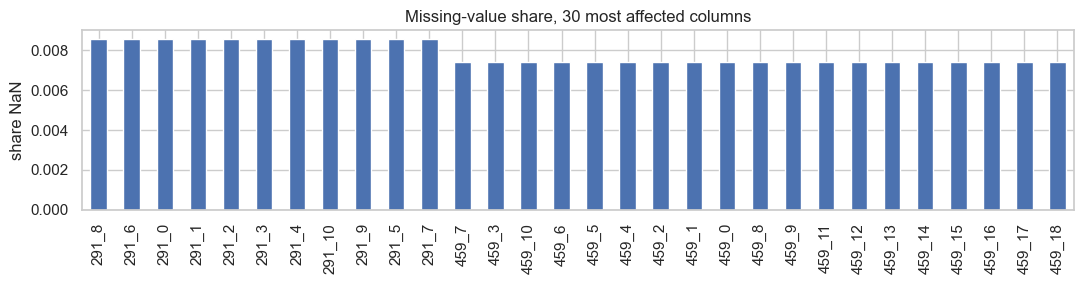

In [6]:
na_share = readouts.drop(columns=["vehicle_id", "time_step"]).isna().mean().sort_values(ascending=False)
print(f"Overall missing share: {readouts.isna().mean().mean():.2%}")
fig, ax = plt.subplots(figsize=(11, 3))
na_share.head(30).plot.bar(ax=ax)
ax.set_title("Missing-value share, 30 most affected columns")
ax.set_ylabel("share NaN")
plt.tight_layout(); plt.show()

### 2.3 Temporal structure — the critical question for PCMCI

Readouts are snapshots taken when the truck communicates, not on a fixed schedule. We measure
(a) series length per vehicle and (b) regularity of the anonymised `time_step` increments.

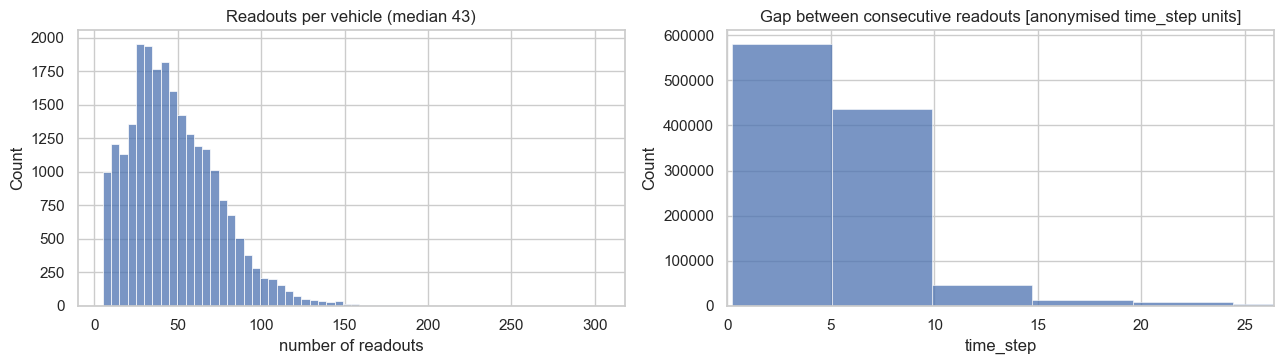

Median gap: 4.4 | IQR: 1.6-6.2 | coefficient of variation: 1.05
Vehicles with >= 100 readouts: 4.4%


In [7]:
per_vehicle = readouts.groupby("vehicle_id")["time_step"].agg(["size", "min", "max"])
gaps = readouts.sort_values(["vehicle_id", "time_step"]).groupby("vehicle_id")["time_step"].diff().dropna()
gaps = gaps[gaps > 0]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(per_vehicle["size"], bins=60, ax=axes[0])
axes[0].set_title(f"Readouts per vehicle (median {per_vehicle['size'].median():.0f})")
axes[0].set_xlabel("number of readouts")
sns.histplot(gaps, bins=80, ax=axes[1])
axes[1].set_xlim(0, gaps.quantile(0.99))
axes[1].set_title("Gap between consecutive readouts [anonymised time_step units]")
plt.tight_layout(); plt.show()

cv = gaps.std() / gaps.mean()
print(f"Median gap: {gaps.median():.1f} | IQR: {gaps.quantile(0.25):.1f}-{gaps.quantile(0.75):.1f} "
      f"| coefficient of variation: {cv:.2f}")
print(f"Vehicles with >= 100 readouts: {(per_vehicle['size'] >= 100).mean():.1%}")

### 2.4 Labels: survival structure and class imbalance

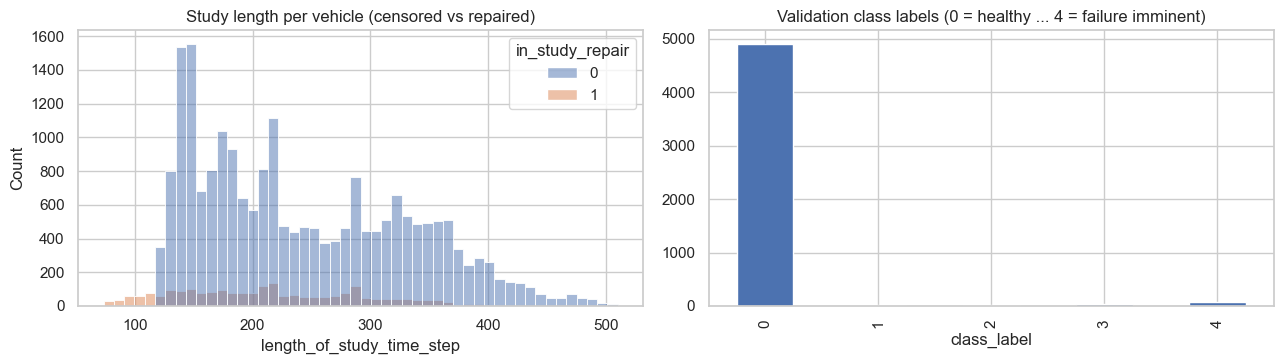

Class shares (validation):
class_label
0    0.9730
1    0.0032
2    0.0028
3    0.0059
4    0.0151
Name: proportion, dtype: float64


In [8]:
val_labels = scania.load_labels("validation")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(data=tte, x="length_of_study_time_step", hue="in_study_repair", bins=50, ax=axes[0])
axes[0].set_title("Study length per vehicle (censored vs repaired)")
val_labels["class_label"].value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set_title("Validation class labels (0 = healthy ... 4 = failure imminent)")
plt.tight_layout(); plt.show()

print("Class shares (validation):")
print(val_labels["class_label"].value_counts(normalize=True).sort_index().round(4))

## 3. Focused EDA — suitability for the causal workflow

### 3.1 Causal Discovery

Three structural obstacles, all by design of the release:

1. **No ground-truth graph** — discovered edges cannot be scored.
2. **Anonymised variables** — an edge `397_23 → 837_0` cannot even be *interpreted* or
   plausibility-checked by a domain expert. This blocks the qualitative validation route that
   anonymous-but-benchmarked datasets would still allow.
3. **Irregular, sparse sampling** (shown in 2.3) — PCMCI's regular-grid assumption requires
   aggressive resampling/aggregation, discarding much of the temporal signal.

Additionally, histogram bins within a family are compositional (they jointly describe a usage
distribution), so we quantify how much redundancy this induces relative to the rest of the
feature set.

In [9]:
# Within-family vs between-family absolute correlation on a vehicle sample
hist_cols = [c for c in readouts.columns if c.split("_")[0] in scania.HISTOGRAM_PREFIXES]
sample = readouts[readouts["vehicle_id"].isin(sample_ids)][hist_cols].dropna()
corr = sample.corr().abs()
fam_of = pd.Series({c: c.split("_")[0] for c in hist_cols})
mask_within = np.equal.outer(fam_of[corr.index].values, fam_of[corr.columns].values)
np.fill_diagonal(mask_within, False)
triu = np.triu(np.ones_like(corr, dtype=bool), k=1)
print(f"Mean |corr| within histogram families : {corr.values[mask_within & triu].mean():.2f}")
print(f"Mean |corr| between histogram families: {corr.values[~mask_within & triu].mean():.2f}")

Mean |corr| within histogram families : 0.41
Mean |corr| between histogram families: 0.39


**Finding.** Mean absolute correlation *within* histogram families (0.41) is barely higher
than *between* families (0.39): redundancy is pervasive across the entire anonymised feature
set, not confined to family blocks. For causal discovery this is the worst case — densely
correlated, uninterpretable variables with no ground truth to arbitrate which edges are real.

### 3.2 Root Cause Analysis

The only failure information is a **binary component-level repair event** (train) or a
**time-window class** (validation/test). There is no cause, no diagnosis, no alarm, no failure
mode — RCA ground truth is entirely absent. At best one can rank *anonymised* features by
association with imminent failure, which is feature importance, not root cause analysis.

In [10]:
# Association ranking demo: last readout of each labelled vehicle vs class label
val_read = scania.load_readouts("validation")
last = val_read.sort_values("time_step").groupby("vehicle_id").last()
joined = last.join(val_labels.set_index("vehicle_id"), how="inner")
failing = joined["class_label"] >= 3
feat_cols = [c for c in last.columns if c != "time_step"]
effect = (
    (joined.loc[failing, feat_cols].mean() - joined.loc[~failing, feat_cols].mean())
    / joined[feat_cols].std()
).abs().sort_values(ascending=False)
effect.head(10).round(2).to_frame("std. shift, failing vs healthy (anonymised features)")

,"std. shift, failing vs healthy (anonymised features)"
397_28,0.56
397_22,0.53
397_4,0.47
397_34,0.44
837_0,0.36
397_16,0.35
397_35,0.30
167_3,0.28
397_6,0.27
397_5,0.27


### 3.3 Interventions

**None, and confounded proxies only.** Repairs are the only "actions" recorded, but they are
triggered *by* the vehicle's condition (classic treatment-by-indication confounding) and the
readouts around them are not flagged. No variable is ever set experimentally, and the
anonymisation (perturbed scales, modified repair frequencies) further distorts any
quasi-experimental signal.

### 3.4 Counterfactual XAI

Counterfactuals could only be generated from a model fitted on anonymised features — and a
counterfactual statement over anonymised variables ("had `459_7` been lower, the component
would not have failed") is not explainable to any stakeholder, which defeats the XAI purpose.
No validation route exists.

### 3.5 Actionable recommendations / dashboard suitability

The *prediction* side is genuinely strong and industrially authentic — fleet-scale survival
analysis with censoring, exactly what a maintenance planner faces. A dashboard can show risk
scores and time-to-failure windows. But recommendations cannot go beyond "schedule workshop
visit": no interpretable variable can be pointed at as the thing to fix.

## 4. Verdict — SCANIA Component X

| Workflow stage | Support | Evidence |
|---|---|---|
| Causal discovery | **Poor** | No ground truth, anonymised variables, irregular sparse sampling (median gap ≫ 0 with high variance) |
| Root cause analysis | **Poor** | Only component-level repair/time-window labels; no causes, no diagnoses |
| Interventions | **None** | Observational; repairs are condition-confounded; anonymisation perturbs scales |
| Counterfactual XAI | **Poor** | Counterfactuals over anonymised features are unexplainable and unvalidatable |
| Actionable recommendations | **Limited** | Excellent for *when* to act (survival/risk), silent on *what* to fix |

**Caveats to carry into the thesis proposal**
1. Data quality itself is good (<1% missing per feature, monotone counters) and documentation
   (Scientific Data paper + PDF annexes) is thorough — the dataset is weak *for this thesis*, not weak in general.
2. Scale (1.1M rows train) makes every experiment slower; a thesis iteration loop suffers.
3. Strongest realistic role: an *external robustness/generalisation* dataset for the predictive
   (non-causal) component of the thesis, or future work.